<a href="https://colab.research.google.com/github/nfathimmain-sketch/Iris_Flower_Streamlit_App/blob/main/Intermediate_assessment_fathima.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import(accuracy_score,
                            precision_score,
                            recall_score,
                            f1_score,
                            classification_report,
                            confusion_matrix,)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier

In [4]:
train = pd.read_csv('/content/drive/MyDrive/DSA/Assessment/train.csv')
test = pd.read_csv('/content/drive/MyDrive/DSA/Assessment/test.csv')
sample_submission = pd.read_csv('/content/drive/MyDrive/DSA/Assessment/sample_submission.csv')

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
train.head()

,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                94 non-null     object 
 1   sexo              94 non-null     object 
 2   longitudCraneo    94 non-null     float64
 3   longitudPico      94 non-null     float64
 4   longitudNarina    94 non-null     float64
 5   anchoCraneo       94 non-null     float64
 6   altoPico          94 non-null     float64
 7   anchoPico         94 non-null     float64
 8   tarso             94 non-null     float64
 9   longAlaCerrada    94 non-null     float64
 10  longAlaAbierta    94 non-null     float64
 11  mediaEnvergadura  94 non-null     float64
 12  envergadura       94 non-null     float64
 13  peso              93 non-null     float64
dtypes: float64(12), object(2)
memory usage: 10.4+ KB


In [8]:
train.shape

(94, 14)

In [9]:
train.columns.to_list()

['id',
 'sexo',
 'longitudCraneo',
 'longitudPico',
 'longitudNarina',
 'anchoCraneo',
 'altoPico',
 'anchoPico',
 'tarso',
 'longAlaCerrada',
 'longAlaAbierta',
 'mediaEnvergadura',
 'envergadura',
 'peso']

In [10]:
train.dtypes

,0
id,object
sexo,object
longitudCraneo,float64
longitudPico,float64
longitudNarina,float64
anchoCraneo,float64
altoPico,float64
anchoPico,float64
tarso,float64
longAlaCerrada,float64


In [11]:
train.isnull().sum()

,0
id,0
sexo,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0


In [12]:
train['peso'] = train['peso'].fillna(train['peso'].median())
train.isnull().sum()

,0
id,0
sexo,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0


In [13]:
train.duplicated().sum()

np.int64(0)

In [14]:
print(train['sexo'].value_counts())
print(train['sexo'].value_counts(normalize=True)*100)

sexo
H    57
M    37
Name: count, dtype: int64
sexo
H    60.638298
M    39.361702
Name: proportion, dtype: float64


In [15]:
test.head()

,id,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,A70_2018,183.57,117.18,87.90,53.60,33.10,26.50,95.70,52.5,98.6,104.4,208.8,3.35
1,5C9_2018,166.60,105.05,80.63,51.64,31.31,26.10,88.82,50.7,93.4,101.4,202.8,2.43
2,5E1_2018,175.53,111.23,84.93,53.74,32.75,24.93,91.42,51.3,94.2,103.4,206.8,2.99
3,C58_2018,187.85,116.90,87.52,54.22,35.10,27.00,99.48,52.3,99.8,107.6,215.2,3.55
4,5E2_2018,182.67,116.40,87.24,54.57,33.59,25.40,96.43,53.4,100.3,110.1,220.2,3.06


In [16]:
test.shape

(41, 13)

In [17]:
test.describe()

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
count,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000
mean,178.985366,111.062195,83.825366,53.016585,33.127805,26.038049,91.924146,51.726829,96.824390,105.373171,210.746341,2.632439
std,6.031885,4.588698,3.556708,2.114764,1.235426,1.134143,3.190172,1.261750,2.558298,2.692678,5.385355,0.429318
min,166.600000,100.810000,75.230000,48.690000,28.850000,23.360000,83.180000,49.400000,91.400000,99.900000,199.800000,2.050000
25%,174.770000,107.690000,81.220000,51.730000,32.570000,25.400000,89.750000,50.700000,95.100000,103.800000,207.600000,2.300000
50%,178.830000,111.400000,83.860000,53.190000,33.020000,26.010000,91.370000,51.500000,96.800000,105.300000,210.600000,2.550000
75%,182.670000,115.440000,87.240000,54.310000,33.950000,26.840000,94.150000,52.800000,98.800000,107.600000,215.200000,2.990000
max,193.220000,117.440000,90.330000,57.330000,35.120000,28.350000,99.480000,54.100000,102.000000,110.100000,220.200000,3.680000


In [18]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                41 non-null     object 
 1   longitudCraneo    41 non-null     float64
 2   longitudPico      41 non-null     float64
 3   longitudNarina    41 non-null     float64
 4   anchoCraneo       41 non-null     float64
 5   altoPico          41 non-null     float64
 6   anchoPico         41 non-null     float64
 7   tarso             41 non-null     float64
 8   longAlaCerrada    41 non-null     float64
 9   longAlaAbierta    41 non-null     float64
 10  mediaEnvergadura  41 non-null     float64
 11  envergadura       41 non-null     float64
 12  peso              41 non-null     float64
dtypes: float64(12), object(1)
memory usage: 4.3+ KB


In [19]:
test.dtypes

,0
id,object
longitudCraneo,float64
longitudPico,float64
longitudNarina,float64
anchoCraneo,float64
altoPico,float64
anchoPico,float64
tarso,float64
longAlaCerrada,float64
longAlaAbierta,float64


In [20]:
test.isnull().sum()

,0
id,0
longitudCraneo,0
longitudPico,0
longitudNarina,0
anchoCraneo,0
altoPico,0
anchoPico,0
tarso,0
longAlaCerrada,0
longAlaAbierta,0


In [21]:
display(train.describe())

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
count,94.000000,94.000000,94.000000,94.000000,94.000000,94.000000,94.00000,94.000000,94.000000,94.000000,94.000000,94.000000
mean,176.580106,110.130426,82.936383,52.687553,32.535000,25.425319,90.88766,51.667021,96.259043,104.765213,209.530426,2.624255
std,5.443278,4.028920,3.187515,2.226749,1.383418,1.439065,2.85098,1.185340,2.187660,2.486498,4.972997,0.314275
min,165.580000,102.710000,74.820000,46.500000,29.340000,21.480000,84.04000,48.700000,88.900000,99.300000,198.600000,2.030000
25%,172.187500,106.835000,80.217500,51.207500,31.605000,24.500000,88.66000,51.000000,94.725000,103.175000,206.350000,2.402500
50%,176.915000,110.070000,83.325000,52.475000,32.605000,25.480000,91.03500,51.600000,96.500000,104.950000,209.900000,2.600000
75%,180.525000,113.252500,85.425000,54.347500,33.460000,26.372500,92.57000,52.475000,97.875000,106.550000,213.100000,2.827500
max,191.210000,119.480000,90.680000,58.360000,35.500000,28.700000,99.69000,54.700000,101.300000,112.200000,224.400000,3.530000


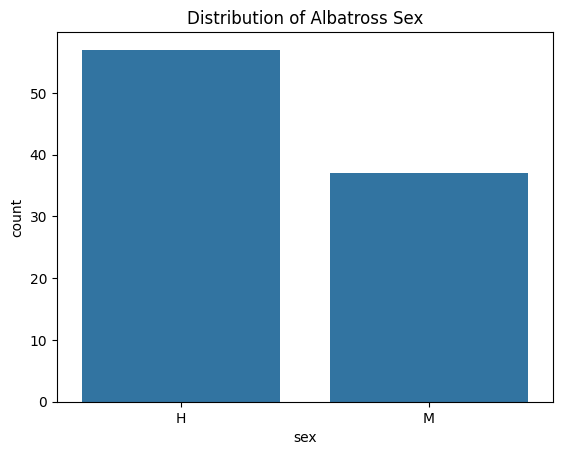

In [22]:
sns.countplot(data=train,x='sexo')
plt.title("Distribution of Albatross Sex")
plt.xlabel('sex')
plt.ylabel('count')
plt.show()

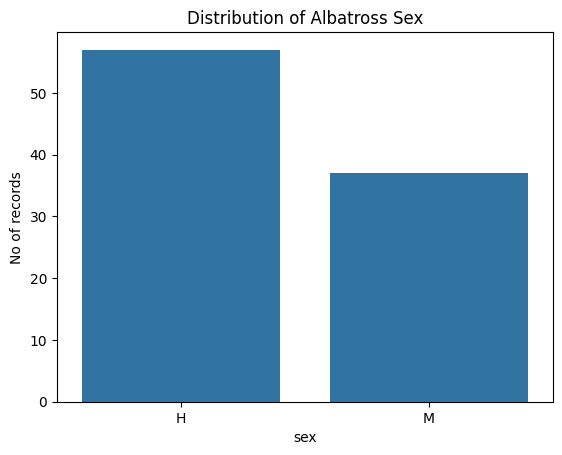

In [23]:
sns.countplot(data=train,x='sexo')
plt.title("Distribution of Albatross Sex")
plt.xlabel('sex')
plt.ylabel('No of records')
plt.show()

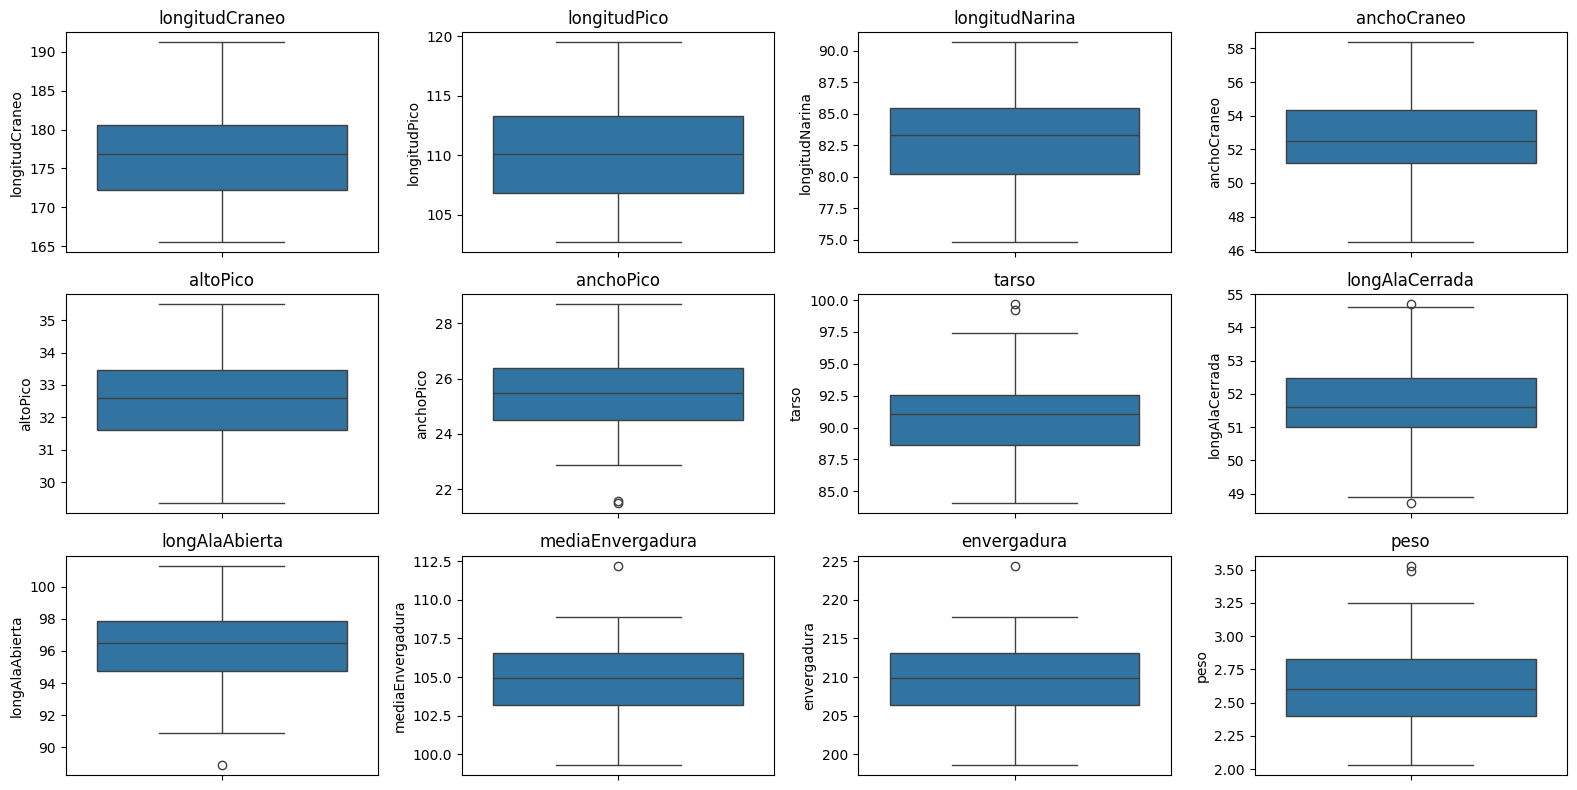

In [24]:
numeric_features = train.drop(columns=["id","sexo"]).select_dtypes(include="number").columns
plt.figure(figsize = (16,8))

for i,col in enumerate(numeric_features,1):
  plt.subplot(3,4,i)
  sns.boxplot(y=train[col])
  plt.title(col)

plt.tight_layout()
plt.show()



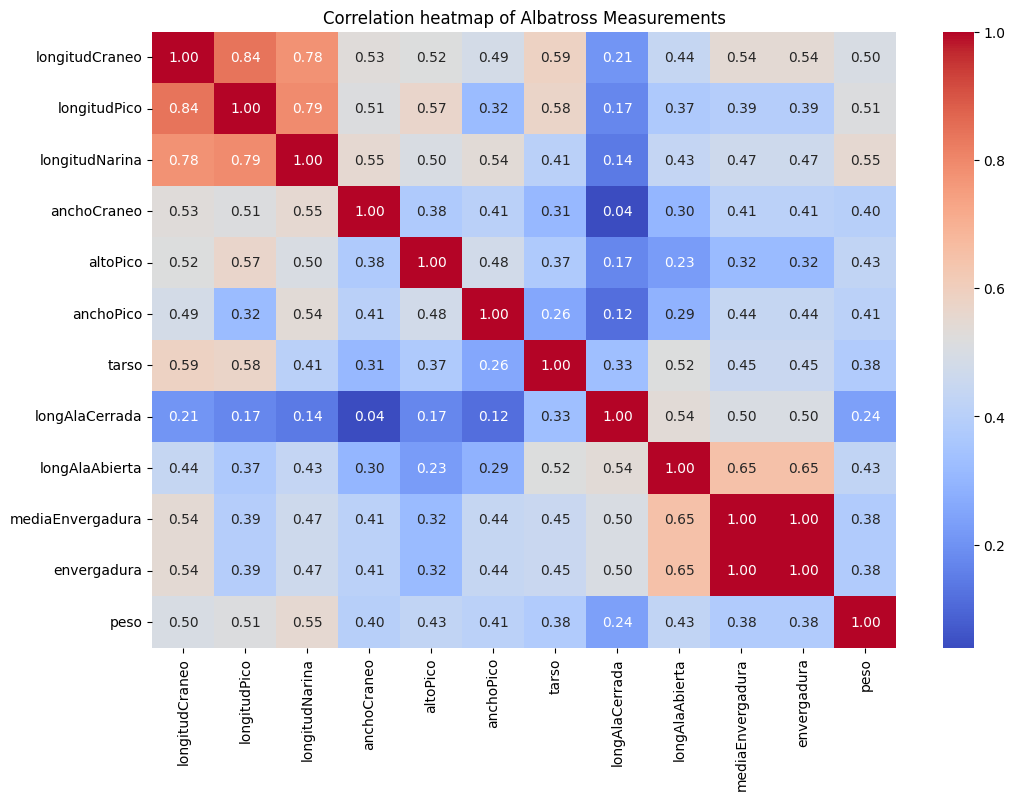

In [25]:
numeric_data = train.drop(columns=['id','sexo']).select_dtypes(include='number')

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    correlation_matrix,
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
)

plt.title('Correlation heatmap of Albatross Measurements')

plt.show()

In [26]:
X = train.drop(columns=["id","sexo"])
y = train["sexo"]

test_ids = test["id"].copy()
X_test = test.drop(columns=["id"])

print("Shape of X:",X.shape)
print("Shape of Y:",y.shape)
print("Shape of X_test:",X_test.shape)

print("\nTarget classes:")
print(y.value_counts())

Shape of X: (94, 12)
Shape of Y: (94,)
Shape of X_test: (41, 12)

Target classes:
sexo
H    57
M    37
Name: count, dtype: int64


In [27]:
print("Same feature columns:", X.columns.equals(X_test.columns))
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())


Same feature columns: True
Missing values in X: 0
Missing values in X_test: 0


In [28]:
X_train,X_valid,y_train,y_valid = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

print("Training Features:",X_train.shape)
print("Validation Features:",X_valid.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_valid.value_counts())

Training Features: (75, 12)
Validation Features: (19, 12)

Training target distribution:
sexo
H    45
M    30
Name: count, dtype: int64

Validation target distribution:
sexo
H    12
M     7
Name: count, dtype: int64


In [29]:
# Model Training
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", ExtraTreesClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced"
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "Trained Successfully")


Logistic Regression Trained Successfully
Random Forest Trained Successfully
Extra Trees Trained Successfully


In [30]:
# Evaluate Models

results = []

for name, model in models.items():
    predictions = model.predict(X_valid)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Macro Precision": precision_score(
            y_valid, predictions,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_valid, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_valid, predictions,
            average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("Macro F1", ascending=False))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.894737,0.886905,0.886905,0.886905
2,Extra Trees,0.894737,0.886905,0.886905,0.886905
1,Random Forest,0.842105,0.839744,0.815476,0.824615


In [31]:
# Inspect the best model


best_model_name = results_df.sort_values(
    "Macro F1", ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]
valid_predictions = best_model.predict(X_valid)

print("Best validation model:", best_model_name)
print("\nClassification report:")
print(classification_report(y_valid, valid_predictions))

print("Confusion matrix:")
print(confusion_matrix(y_valid, valid_predictions))


Best validation model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19

Confusion matrix:
[[11  1]
 [ 1  6]]


In [32]:
# Train the final model


# Select Logistic Regression
final_model = models["Logistic Regression"]

# Train using the complete labeled dataset
final_model.fit(X, y)

print("Final model trained successfully!")

# Predict the test dataset
test_predictions = final_model.predict(X_test)

print("\nFirst 10 predictions:")
print(test_predictions[:10])

print("\nPrediction counts:")
print(pd.Series(test_predictions).value_counts())


Final model trained successfully!

First 10 predictions:
['M' 'H' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M']

Prediction counts:
H    21
M    20
Name: count, dtype: int64


In [33]:
print("Sample submission columns:")
print(sample_submission.columns.tolist())

display(sample_submission.head())


Sample submission columns:
['id', 'sexo']


,id,sexo
0,id_1,M
1,id_2,H
2,id_3,M


In [34]:

# Create the submission using all test records
submission = pd.DataFrame({
    "id": test["id"].values,
    "sexo": test_predictions
})

# Check the result
print("Submission shape:", submission.shape)
display(submission.head())

# Check the number of predictions
print("Number of test records:", len(test))
print("Number of predictions:", len(test_predictions))

# Save the file
submission.to_csv("submission.csv", index=False)

print("submission.csv created successfully!")



Submission shape: (41, 2)


,id,sexo
0,A70_2018,M
1,5C9_2018,H
2,5E1_2018,M
3,C58_2018,M
4,5E2_2018,M


Number of test records: 41
Number of predictions: 41
submission.csv created successfully!
